importing dependencies

In [22]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn import metrics

Data Collection and Processing

In [3]:
# loading the csv data to a pandas df
gold_data = pd.read_csv('/content/gld_price_data.csv')

In [4]:
# show df head
gold_data.head()

,Date,SPX,GLD,USO,SLV,EUR/USD
0,1/2/2008,1447.160034,84.860001,78.470001,15.180,1.471692
1,1/3/2008,1447.160034,85.570000,78.370003,15.285,1.474491
2,1/4/2008,1411.630005,85.129997,77.309998,15.167,1.475492
3,1/7/2008,1416.180054,84.769997,75.500000,15.053,1.468299
4,1/8/2008,1390.189941,86.779999,76.059998,15.590,1.557099


In [5]:
# print last 5 rows of the df
gold_data.tail()

,Date,SPX,GLD,USO,SLV,EUR/USD
2285,5/8/2018,2671.919922,124.589996,14.0600,15.5100,1.186789
2286,5/9/2018,2697.790039,124.330002,14.3700,15.5300,1.184722
2287,5/10/2018,2723.070068,125.180000,14.4100,15.7400,1.191753
2288,5/14/2018,2730.129883,124.489998,14.3800,15.5600,1.193118
2289,5/16/2018,2725.780029,122.543800,14.4058,15.4542,1.182033


In [6]:
# number of rows and column
gold_data.shape

(2290, 6)

In [7]:
# getting some basic informations about the data
gold_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2290 entries, 0 to 2289
Data columns (total 6 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   Date     2290 non-null   object 
 1   SPX      2290 non-null   float64
 2   GLD      2290 non-null   float64
 3   USO      2290 non-null   float64
 4   SLV      2290 non-null   float64
 5   EUR/USD  2290 non-null   float64
dtypes: float64(5), object(1)
memory usage: 107.5+ KB


In [8]:
#checking for missing values
gold_data.isnull().sum()

,0
Date,0
SPX,0
GLD,0
USO,0
SLV,0
EUR/USD,0


In [9]:
# statistical vmeasures of the data
gold_data.describe()

,SPX,GLD,USO,SLV,EUR/USD
count,2290.000000,2290.000000,2290.000000,2290.000000,2290.000000
mean,1654.315776,122.732875,31.842221,20.084997,1.283653
std,519.111540,23.283346,19.523517,7.092566,0.131547
min,676.530029,70.000000,7.960000,8.850000,1.039047
25%,1239.874969,109.725000,14.380000,15.570000,1.171313
50%,1551.434998,120.580002,33.869999,17.268500,1.303297
75%,2073.010070,132.840004,37.827501,22.882500,1.369971
max,2872.870117,184.589996,117.480003,47.259998,1.598798


Correlation:

1. Positive correlation
2. Negative correlation

In [11]:
correlation = gold_data.corr(numeric_only=True)

<Axes: >

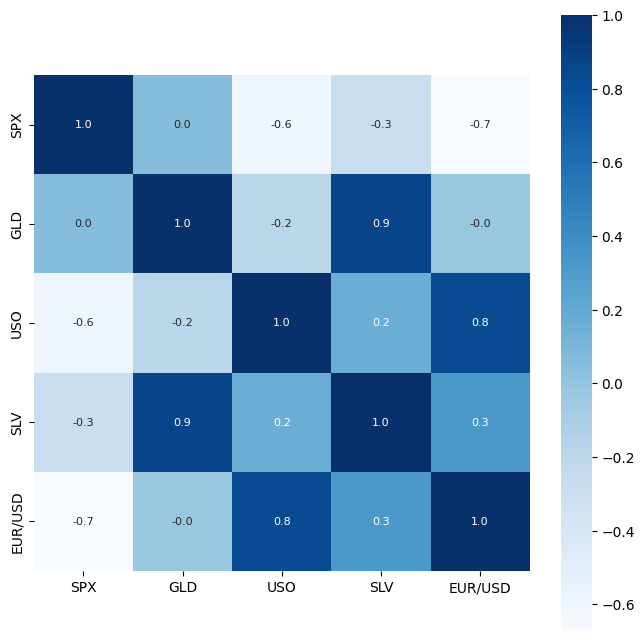

In [12]:
# constructing a heatmap to understand the correlation
plt.figure(figsize=(8,8))
sns.heatmap(correlation, cbar=True, square=True, fmt='.1f', annot=True, annot_kws={'size':8}, cmap='Blues')

In [13]:
# correlation values of GLD
print(correlation['GLD'])

SPX        0.049345
GLD        1.000000
USO       -0.186360
SLV        0.866632
EUR/USD   -0.024375
Name: GLD, dtype: float64


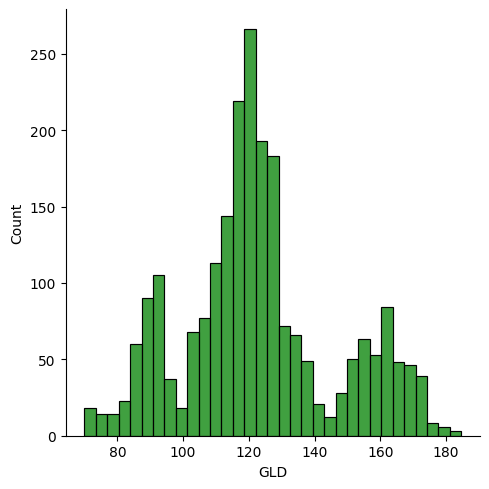

In [14]:
# check for distribution of the gold price
sns.displot(gold_data['GLD'], color='green')

splitting the features and target

In [15]:
X = gold_data.drop(['Date','GLD'], axis=1)
Y = gold_data['GLD']

In [17]:
print(X)

              SPX        USO      SLV   EUR/USD
0     1447.160034  78.470001  15.1800  1.471692
1     1447.160034  78.370003  15.2850  1.474491
2     1411.630005  77.309998  15.1670  1.475492
3     1416.180054  75.500000  15.0530  1.468299
4     1390.189941  76.059998  15.5900  1.557099
...           ...        ...      ...       ...
2285  2671.919922  14.060000  15.5100  1.186789
2286  2697.790039  14.370000  15.5300  1.184722
2287  2723.070068  14.410000  15.7400  1.191753
2288  2730.129883  14.380000  15.5600  1.193118
2289  2725.780029  14.405800  15.4542  1.182033

[2290 rows x 4 columns]


Separatting into training data and testing data

In [18]:
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=2)

Model Training:

Random Forest Regressor

In [25]:
regressor = RandomForestRegressor(n_estimators=100)

In [26]:
# training the model
regressor.fit(X_train,Y_train)

RandomForestRegressor()

Model evaluation

In [27]:
# prediction on test data
test_data_prediction = regressor.predict(X_test)


In [28]:
print(test_data_prediction)

[168.64099976  81.62910007 116.03739977 127.69110066 120.64120164
 154.85189723 150.35329831 125.99090018 117.4790988  126.06570079
 116.95480059 172.04110073 141.63569797 167.84509795 115.24660024
 117.42950039 139.90520296 170.28450134 159.94180275 158.17419958
 155.13920036 125.19490007 175.90079952 157.16570315 125.23220051
  93.94989966  77.97599993 120.94230012 119.02979909 167.41939989
  88.35570051 125.35509973  91.06230045 117.72929997 121.03369986
 135.67440056 115.39610131 115.00530059 147.93929947 107.01640093
 104.84930265  87.16999788 126.56350051 118.0053999  152.92279881
 119.63640009 108.40519966 107.93599837  93.26730054 127.29169715
  75.26450031 113.77479966 121.42060015 111.23619932 118.73249872
 120.22749934 158.27820015 170.02840074 146.9036972   85.84409831
  94.2927002   86.7950991   90.64380025 119.07150054 126.46450067
 127.54609993 168.72099975 122.26549924 117.48759935  98.65300044
 168.23000155 142.86529974 131.51770276 121.29160219 121.0180994
 119.648500

In [29]:
# R squared error
error_score = metrics.r2_score(Y_test,test_data_prediction)
print("R squared error: ", error_score)

R squared error:  0.9888294273246101


Compare actual values and predicted values in a plot

In [31]:
 Y_test = list(Y_test)

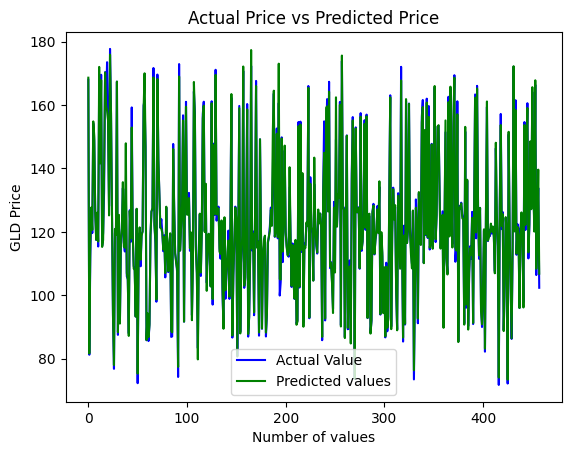

In [33]:
plt.plot(Y_test, color='blue' , label = 'Actual Value')
plt.plot(test_data_prediction, color='green' , label= 'Predicted values')
plt.title('Actual Price vs Predicted Price')
plt.xlabel('Number of values')
plt.ylabel('GLD Price')
plt.legend()
plt.show()